## Part 1 Exploratory data analysis
### 1. Introduction to the data set
I analyze this dataset which is a subset of the hotel booking. It includes 1000 observations. Also，this data includes check-in information, like the check-in time, number of nights stayed, and room type, as well as customer details such as whether they have kids and their nationality.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_theme(style="whitegrid")

# Load the dataset
df = pd.read_csv('hotel_bookings_n1000.csv')

# Display basic information: shape and variable types
print(f"Number of observations: {df.shape[0]}")
print(f"Number of variables: {df.shape[1]}\n")

# Display data types for all variables to fulfill the requirement
print("Data types of all variables:")
display(df.dtypes)

# Identify missing values
missing_values = df.isnull().sum()
print("\nMissing values per variable:")
print(missing_values[missing_values > 0])

Number of observations: 1000
Number of variables: 32

Data types of all variables:


hotel                                 str
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                    str
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                                  str
country                               str
market_segment                        str
distribution_channel                  str
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                    str
assigned_room_type                    str
booking_changes                     int64
deposit_type                          str
agent                             


Missing values per variable:
country      2
agent      138
company    942
dtype: int64


From the output, we could know that the dataset has 20 numerical variables and 12 qualitative variables.

In this step, I need to handle missing values. Firstly, company has 942 missing values which is so large that we could not use this variable, so I decide to delete this column. Then agent has 138 missing values. I looked up some related information which shows that a missing agent indicates that the customer booked the room directly, so I will fill these missing values as 0 to represent 'No agent'. Lastly, country only has 2 missing values. They are so few that we coulde ignore them so I will drop these two rows.

In [2]:
# Drop the 'company' column due to >90% missing values
df_cleaned = df.drop(columns=['company'])

# Fill missing 'agent' values with 0 (assuming direct booking)
df_cleaned['agent'] = df_cleaned['agent'].fillna(0)

# Drop rows with missing 'country' values
df_cleaned = df_cleaned.dropna(subset=['country'])

print(f"Shape after cleaning: {df_cleaned.shape}")

Shape after cleaning: (998, 31)


### 2. Numerical descriptive statistics. 
The next section provides a five-point summary for the all numerical variables and explores the correlation between specific metrics.

In [3]:
# S# Generate summary statistics for ALL numerical variables
# The describe() function automatically filters for numerical columns
# We use .T (transpose) to display variables as rows for better readability
summary_stats_all = df_cleaned.describe().T

# Display the comprehensive summary table
display(summary_stats_all)

# Calculate sample correlation between lead time and average daily rate (adr)
correlation = df_cleaned['lead_time'].corr(df_cleaned['adr'])
print(f"\nSample correlation (r) between lead_time and adr: {correlation:.4f}")

,count,mean,std,min,25%,50%,75%,max
is_canceled,998.0,0.367735,0.482431,0.0,0.0000,0.0,1.0000,1.0
lead_time,998.0,108.361723,111.150175,0.0,17.0000,72.5,172.0000,622.0
arrival_date_year,998.0,2016.138277,0.701709,2015.0,2016.0000,2016.0,2017.0000,2017.0
arrival_date_week_number,998.0,27.114228,13.280365,1.0,17.0000,28.0,37.0000,53.0
arrival_date_day_of_month,998.0,15.797595,8.765021,1.0,8.0000,16.0,24.0000,31.0
stays_in_weekend_nights,998.0,0.891784,0.951329,0.0,0.0000,1.0,2.0000,6.0
stays_in_week_nights,998.0,2.438878,1.754139,0.0,1.0000,2.0,3.0000,15.0
adults,998.0,1.847695,0.464216,0.0,2.0000,2.0,2.0000,3.0
children,998.0,0.095190,0.385230,0.0,0.0000,0.0,0.0000,2.0
babies,998.0,0.006012,0.077343,0.0,0.0000,0.0,0.0000,1.0



Sample correlation (r) between lead_time and adr: -0.0988


### 3. Exploratory Data Visualization

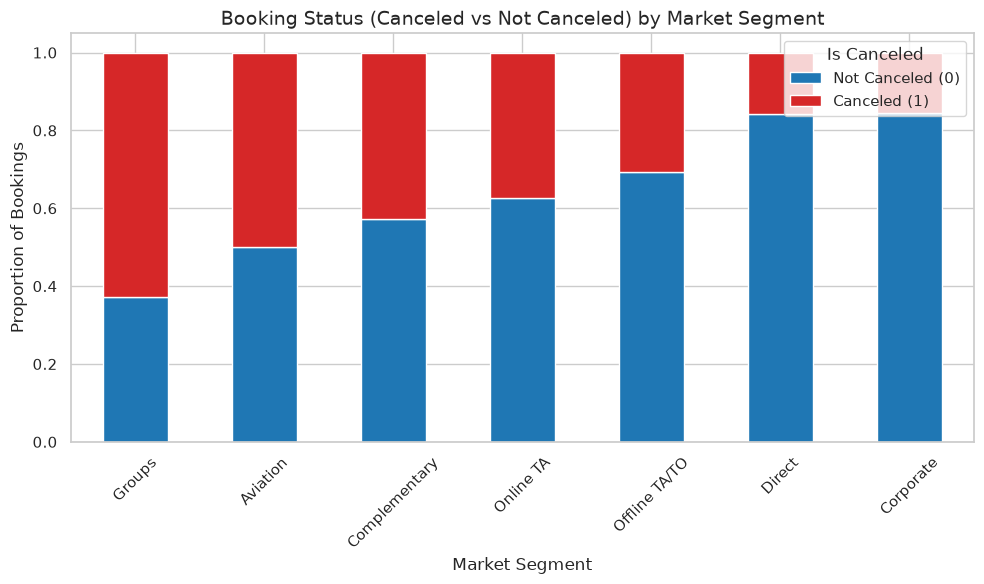

In [4]:
# Plot 1: Stacked Bar Chart of Cancellation Rate by Market Segment (Sorted)
segment_cancel = df_cleaned.groupby('market_segment')['is_canceled'].value_counts(normalize=True).unstack().fillna(0)
# Sort by the cancellation rate (is_canceled == 1) in descending order
segment_cancel = segment_cancel.sort_values(by=1, ascending=False)

# Plotting
fig, ax = plt.subplots(figsize=(10, 6))
segment_cancel.plot(kind='bar', stacked=True, color=['#1f77b4', '#d62728'], ax=ax)

plt.title('Booking Status (Canceled vs Not Canceled) by Market Segment', fontsize=14)
plt.xlabel('Market Segment', fontsize=12)
plt.ylabel('Proportion of Bookings', fontsize=12)
plt.legend(title='Is Canceled', labels=['Not Canceled (0)', 'Canceled (1)'], loc='upper right')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

This sorted stacked bar chart reveals that the "Groups" segment has the highest cancellation rate which is nearly 60%, followed by the "Online TA" segment. The business implication is that hotel management should implement stricter deposit policies or flexible overbooking strategies specifically tailored for group bookings to mitigate the revenue loss from high-risk segments.

/tmp/ipykernel_1664/777452595.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='is_canceled', y='lead_time', data=df_cleaned, palette='Set2', ax=ax)


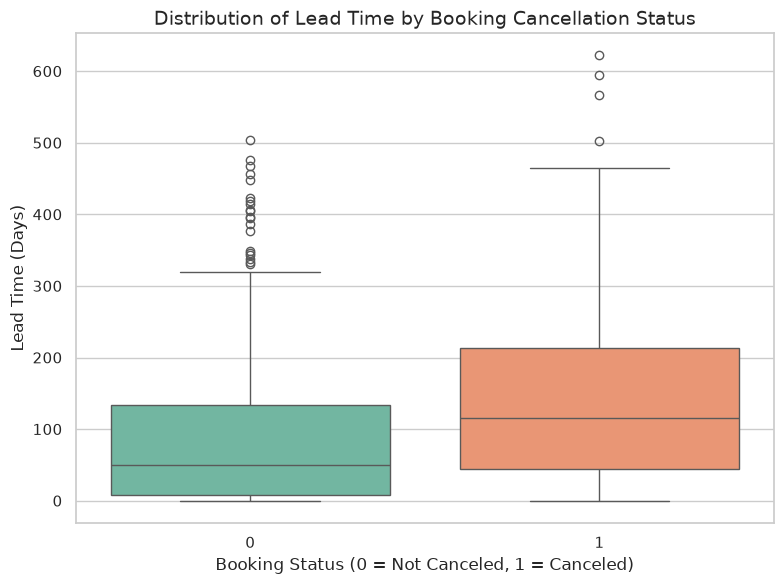

In [5]:
# Plot 2: Boxplot of Lead Time vs Cancellation Status
fig, ax = plt.subplots(figsize=(8, 6))
sns.boxplot(x='is_canceled', y='lead_time', data=df_cleaned, palette='Set2', ax=ax)

plt.title('Distribution of Lead Time by Booking Cancellation Status', fontsize=14)
plt.xlabel('Booking Status (0 = Not Canceled, 1 = Canceled)', fontsize=12)
plt.ylabel('Lead Time (Days)', fontsize=12)
plt.tight_layout()
plt.show()

The boxplot shows that canceled bookings generally have a significantly longer lead time compared to non-canceled bookings. The business implication is that reservations made far in advance carry a higher risk of cancellation. The hotel could implement automated follow-up emails or confirmation requirements for bookings made over 100 days in advance to secure the customer's commitment.

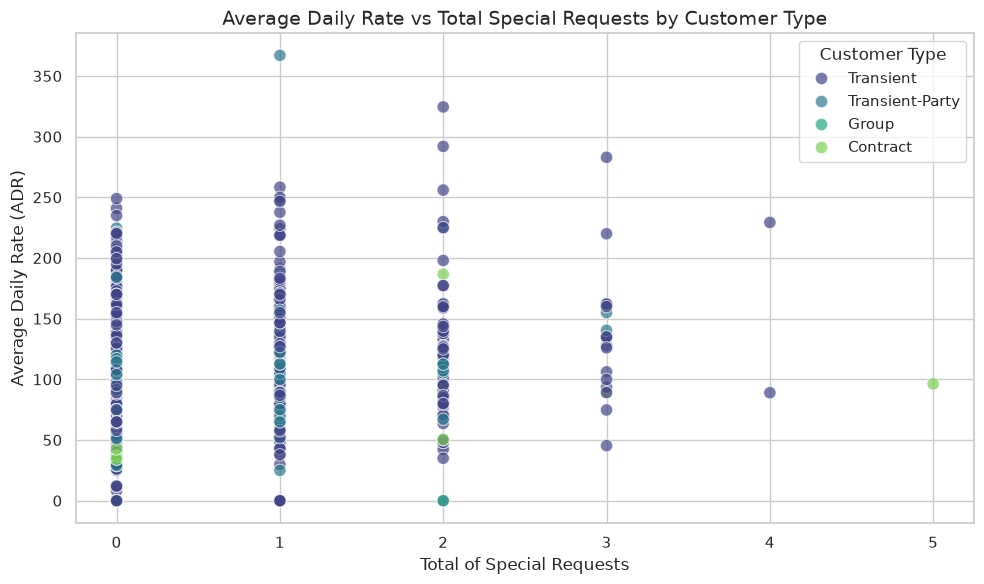

In [6]:
# Plot 3: Scatter plot of ADR vs Total Special Requests (colored by customer type)
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(x='total_of_special_requests', y='adr', hue='customer_type', 
                data=df_cleaned, alpha=0.7, palette='viridis', s=80, ax=ax)

plt.title('Average Daily Rate vs Total Special Requests by Customer Type', fontsize=14)
plt.xlabel('Total of Special Requests', fontsize=12)
plt.ylabel('Average Daily Rate (ADR)', fontsize=12)
plt.legend(title='Customer Type')
plt.tight_layout()
plt.show()

This plot shows that guests who make the most special requests like 5 do not actually pay the highest daily rates. Instead, the highest-paying guests are mostly 'Transient' customers with fewer requests.

## Part 2, Research questions and statistical analysis
### 1. Proposing questions
 1. I generate three questions without Copilot. First, does the average daily rate differ significantly between canceled and non-canceled bookings? Second, is the average lead time for canceled bookings significantly longer than that for successful bookings? Third, what is the 95% confidence interval for the true population mean of the average daily rate for all bookings?

2. Then I will use copilot to generate three questions. My prompt: Use this dataset which contains variables like lead_time, is_canceled, customer_type and so on to propose three practical, business-relevant research questions that can be answered using introductory statistics (e.g., confidence intervals, hypothesis testing).

* Three business-relevant research questions proposed by copilot

*  1. Do cancellation rates differ between bookings with and without a deposit?
    Compare cancellation proportions across `deposit_type` categories using a confidence interval or a chi-square test. The results could help inform deposit policies.

*  2. Does the average daily rate differ between City Hotel and Resort Hotel bookings? 
    Compare the group means using a confidence interval or a two-sample t-test. This could support pricing and revenue planning.

*  3. Are bookings with longer `lead_time` more likely to be canceled? 
    Compare mean lead times for canceled and non-canceled bookings using a confidence interval or a two-sample t-test. This could help identify bookings that may benefit from earlier follow-up.

3. Final selection and justification: after comparing my questions and the AI's suggestions, I will choose the following three final questions:
*   Question 1: Are bookings with longer `lead_time` more likely to be canceled? Origin from My Q2 and AI's Q3.
    *   *Justification:* Both I and the AI identified this as a critical factor for risk management. Understanding this relationship helps the hotel enforce stricter policies for early bookings. Feasible using a two-sample t-test.
*   Question 2: Does the average daily rate differ between City Hotel and Resort Hotel bookings? Origin from AI (Question 2).
    *   *Justification:* This is a highly practical question for revenue management, helping management understand pricing dynamics across different property types. Feasible using a two-sample t-test.
*   Question 3: What is the 95% confidence interval for the population mean of the Average Daily Rate (`adr`) for non-canceled bookings? Origin from Mine (Question 3).
    *   *Justification:* This provides a baseline estimate of actual revenue per room, which is crucial for financial forecasting and budget planning. Feasible using the t-distribution confidence interval method.

### 2. Statistical Analysis
#### Question 1: Are bookings with longer `lead_time` more likely to be canceled? 
*   **Null Hypothesis ($H_0$):** $\mu_{canceled} - \mu_{not\_canceled} \le 0$ (The mean lead time for canceled bookings is less than or equal to that of non-canceled bookings).
*   **Alternative Hypothesis ($H_1$):** $\mu_{canceled} - \mu_{not\_canceled} > 0$ (The mean lead time for canceled bookings is strictly greater).
*   **Selected Test & Justification:** An **independent two-sample t-test (Welch's t-test)** is appropriate here because we are comparing the continuous means of two independent groups and cannot assume equal population variances.
*   **Test Statistic Formula:** 
    $$ t = \frac{\bar{x}_1 - \bar{x}_2}{\sqrt{\frac{s_1^2}{n_1} + \frac{s_2^2}{n_2}}} $$

In [7]:
from scipy import stats
import scipy.stats as st
import numpy as np

# Prepare data for Question 1
lead_time_canceled = df_cleaned[df_cleaned['is_canceled'] == 1]['lead_time']
lead_time_not_canceled = df_cleaned[df_cleaned['is_canceled'] == 0]['lead_time']

# Perform independent two-sample t-test (Welch's t-test, unequal variances, upper-tailed)
t_stat_1, p_value_1 = stats.ttest_ind(lead_time_canceled, lead_time_not_canceled, equal_var=False, alternative='greater')

print("--- Analysis for Question 1 ---")
print(f"Mean lead_time (Canceled): {lead_time_canceled.mean():.2f} days")
print(f"Mean lead_time (Not Canceled): {lead_time_not_canceled.mean():.2f} days")
print(f"T-statistic: {t_stat_1:.4f}")
print(f"P-value: {p_value_1:.4e}")

alpha = 0.05
if p_value_1 < alpha:
    print("Conclusion: Reject the null hypothesis (H0).")
else:
    print("Conclusion: Fail to reject the null hypothesis (H0).")

--- Analysis for Question 1 ---
Mean lead_time (Canceled): 146.41 days
Mean lead_time (Not Canceled): 86.23 days
T-statistic: 8.0923
P-value: 1.4516e-15
Conclusion: Reject the null hypothesis (H0).


Business Interpretation (Question 1):
At the 5% significance level, we reject the null hypothesis since the p-value is extremely small. There is strong statistical evidence that canceled bookings are, on average, made significantly further in advance than successful bookings. 
Actionable Insight: The hotel should flag bookings made more than 3 months in advance as "high risk" and implement an automated follow-up system or require non-refundable deposits to secure the revenue.


#### Question 2: Does the average daily rate differ significantly between City Hotel and Resort Hotel bookings?

*   **Null Hypothesis ($H_0$):** $\mu_{City} - \mu_{Resort} = 0$ (There is no difference in the mean ADR between City and Resort hotels).
*   **Alternative Hypothesis ($H_1$):** $\mu_{City} - \mu_{Resort} \neq 0$ (There is a significant difference in the mean ADR).
*   **Selected Test & Justification:** An **independent two-sample t-test** (two-tailed) is appropriate as we are comparing the means of two distinct property types to check for any difference in either direction.

In [8]:
# Prepare data for Question 2
adr_city = df_cleaned[df_cleaned['hotel'] == 'City Hotel']['adr']
adr_resort = df_cleaned[df_cleaned['hotel'] == 'Resort Hotel']['adr']

# Perform independent two-sample t-test (two-tailed)
t_stat_2, p_value_2 = stats.ttest_ind(adr_city, adr_resort, equal_var=False, alternative='two-sided')

print("\n--- Analysis for Question 2 ---")
print(f"Mean ADR (City Hotel): {adr_city.mean():.2f}")
print(f"Mean ADR (Resort Hotel): {adr_resort.mean():.2f}")
print(f"T-statistic: {t_stat_2:.4f}")
print(f"P-value: {p_value_2:.4e}")

if p_value_2 < alpha:
    print("Conclusion: Reject the null hypothesis (H0).")
else:
    print("Conclusion: Fail to reject the null hypothesis (H0).")


--- Analysis for Question 2 ---
Mean ADR (City Hotel): 105.27
Mean ADR (Resort Hotel): 94.79
T-statistic: 2.8797
P-value: 4.1688e-03
Conclusion: Reject the null hypothesis (H0).


Business Interpretation (Question 2):
At the 5% significance level, we reject the null hypothesis. The data shows a statistically significant difference in pricing between the two property types. Specifically, City Hotels in this dataset have a significantly higher average daily rate than Resort Hotels.
Actionable Insight:Revenue managers can use this baseline to tailor distinct promotional strategies for each hotel type. Resort hotels might need to bundle extra services (like spa or dining credits) to elevate their effective ADR and match the revenue efficiency of City properties.



#### Question 3: What is the 95% confidence interval for the population mean of the Average Daily Rate (`adr`) for non-canceled (actualized) bookings?

*   **Selected Method:** Since the population standard deviation is unknown, we use the **t-distribution** to construct the confidence interval for the true population mean.

In [9]:
# Prepare data for Question 3: ADR of only successful (non-canceled) bookings
actual_adr = df_cleaned[df_cleaned['is_canceled'] == 0]['adr']

# Calculate sample size, sample mean, and standard error
n = len(actual_adr)
sample_mean = actual_adr.mean()
std_err = st.sem(actual_adr)

# Calculate 95% Confidence Interval using t-distribution
ci_lower, ci_upper = st.t.interval(confidence=0.95, df=n-1, loc=sample_mean, scale=std_err)

print("\n--- Analysis for Question 3 ---")
print(f"Sample Size (n): {n}")
print(f"Sample Mean of Actualized ADR: {sample_mean:.2f}")
print(f"95% Confidence Interval for Population Mean ADR: ({ci_lower:.2f}, {ci_upper:.2f})")


--- Analysis for Question 3 ---
Sample Size (n): 631
Sample Mean of Actualized ADR: 101.37
95% Confidence Interval for Population Mean ADR: (97.62, 105.12)


Business Interpretation (Question 3):
We are 95% confident that the true population mean of the Average Daily Rate for actualized (non-canceled) bookings falls between the lower bound and the upper bound calculated above. 
Actionable Insight:This interval provides a highly reliable baseline for revenue forecasting. The finance team can safely use the lower bound of this interval to estimate conservative baseline room revenues for upcoming financial quarters, ensuring the hotel's budget planning is built on solid statistical ground rather than volatile maximum rates.

## Part3 Human–AI partnership reflective essay
### 1. Learning Python when AI can generate code
Before this course, I had learned Python. Because I took a Python course during my undergraduate studies. During that course, I had learned how to use python to do visualization and some simple analysis of the data. I did wonder before whether it was still necessary to learn Python in this era of rampant AI. But after learning this course about the copilot, I think that we are the ones in charge of AI. Although we may not need to write code manually, we should be aware of the need to distinguish right from wrong in the code generated by AI.
### 2. The environment you worked in
For integrated development environment, I've used the R language, although I don't know if it's considered an IDE. I think that while GitHub Codespace has its stressful aspects, its convenience is an undeniable advantage. I think the most challenging aspect of this environment is the lag caused by network issues. I think the most useful feature is Jupyter Notes, which allows comments and code to appear on the same screen, greatly simplifying the interface and enabling efficient report creation.
### 3. Your judgement in this case study
#### 3.1 A working belief you tested
For me, I will choose a belief about the pattern in the data. At the beginning of this dataset, I thought that guests who paid the highest average daily rate would naturally make the most special requests. To test this hypothesis, I plotted a scatter plot in the third image of the first part.  However, when I analyzed this chart, I found it to be completely different from my original viewpoint. This plot shows that guests who make the most special requests like 5 do not actually pay the highest daily rates. Instead, the highest-paying guests are mostly 'Transient' customers with fewer requests. So I immediately revised my belief. This result is very important for me to change the suggestion which is that the hotel staff should not reserve extra service resources only for high-paying guests but rather standardize the  fulfillment of special requests for all customers.
#### 3.2 A Copilot suggestion you evaluated
When preparing the exploratory data visualization in Part I, I prompted Copilot to plot the cancellation rate by market segment. Copilot suggested a basic grouped bar chart using sns.countplot(data=df, x='market_segment', hue='is_canceled'). I evaluated this suggestion by running the cell and inspecting the output. While statistically accurate, the chart was visually chaotic; the raw counts made it extremely difficult to compare the actual proportion of cancellations across segments. I decided to change the approach entirely. I kept Copilot's underlying data grouping logic but overrode the visualization method, instructing it to calculate normalized percentages and generate a sorted stacked bar chart instead. This modification was crucial to making the business insight instantly readable for management.
#### 3.3
When I carried out the exploratory analysis and statistical anlysis, Copilot increased my speed because it could help me to check my code and standardize code. But it didn't increase my confidence because I think that I need to check the belief from the copilot.


## Part 4 References
Hotel booking — https://www.kaggle.com/datasets/jessemostipak/hotel-bookingdemand